In [2]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

ModuleNotFoundError: No module named 'pandas'

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 23.4 MB/s  0:00:00a 0:00:0136m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 30.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 31.8 MB/s  0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 30.3 MB/s  0:00:00 89.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 30.9 MB/s  0:00:01 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 28.6 MB/s  0:00:02 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 27.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 26.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 26.4 MB/s  0:00:10 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [imbalanced-learn]2m19/20 [imbalanced-learn]

[notice] A new rele

In [1]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

FileNotFoundError: [Errno 2] No such file or directory: '../data/creditcard.csv'

In [2]:
import os
print(os.getcwd())
print(os.listdir(".."))
print(os.listdir("../data") if os.path.exists("../data") else "no data folder")

/workspaces/credit-card-fraud-detection
['.codespaces', '.oryx', 'credit-card-fraud-detection']
no data folder


In [3]:
mkdir -p data

In [4]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

FileNotFoundError: [Errno 2] No such file or directory: '../data/creditcard.csv'

In [5]:
import os
print("Current folder:", os.getcwd())
print("Files here:", os.listdir("."))
print("Files one level up:", os.listdir(".."))

Current folder: /workspaces/credit-card-fraud-detection
Files here: ['README.md', 'requirements.txt', 'data', '01_eda.ipynb', '.gitignore', '.ipynb_checkpoints', 'outputs', '.git', 'LICENSE', 'notebooks']
Files one level up: ['.codespaces', '.oryx', 'credit-card-fraud-detection']


In [6]:
import glob
print(glob.glob("/workspaces/**/creditcard*", recursive=True))

['/workspaces/credit-card-fraud-detection/data/creditcard.csv']


In [7]:
import pandas as pd

df = pd.read_csv("/workspaces/credit-card-fraud-detection/data/creditcard.csv")

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicate rows")

counts = df["Class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(3))

print(df.groupby("Class")["Amount"].describe())

(284807, 31)
0 missing values
1081 duplicate rows
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827
1     0.173
Name: count, dtype: float64
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [10]:
from pathlib import Path

path = Path("data/creditcard.csv")
if not path.exists():
    path = Path("../data/creditcard.csv")

df = pd.read_csv(path)

In [11]:
dups = df[df.duplicated(keep=False)]
print(dups["Class"].value_counts())
print("Fraud rows among duplicates removed:", df[df.duplicated()]["Class"].sum())

Class
0    1822
1      32
Name: count, dtype: int64
Fraud rows among duplicates removed: 19


In [12]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df["Class"].value_counts())

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


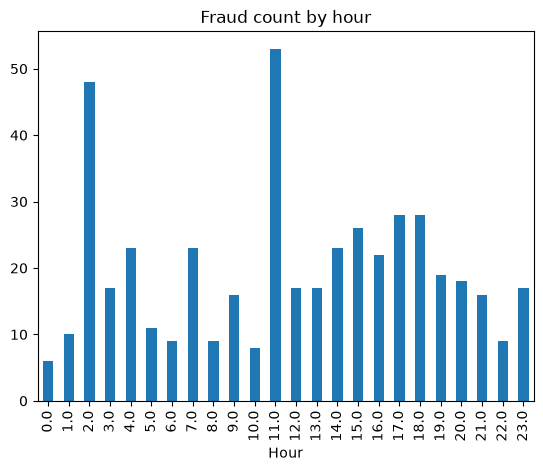

In [13]:
import matplotlib.pyplot as plt

df["Hour"] = (df["Time"] // 3600) % 24
df[df["Class"] == 1]["Hour"].value_counts().sort_index().plot(
    kind="bar", title="Fraud count by hour"
)
plt.show()

In [14]:
git add notebooks/01_eda.ipynb
git commit -m "Add EDA notebook with class imbalance analysis"
git push origin main

SyntaxError: invalid decimal literal (4015851637.py, line 1)